# Bellabeat case study: analysis

Data is read directly from the `fitbit_mart` star schema in BigQuery
(see `docs/data_model.md`). Each section tests one hypothesis and ends
with a one-sentence finding.

## 0. Setup and data load

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery

PROJECT_ID = "bellabeat-case-study-513614"
client = bigquery.Client(project=PROJECT_ID)

def run_query(sql):
    return client.query(sql).to_dataframe(create_bqstorage_client=False)

In [2]:
run_query("""
SELECT activity_segment, COUNT(*) AS users
FROM fitbit_mart.dim_user
GROUP BY activity_segment, activity_segment_order
ORDER BY activity_segment_order
""")

,activity_segment,users
0,Sedentary,9
1,Low active,8
2,Somewhat active,9
3,Active,9


In [3]:
tables = [
    "dim_user", "dim_date", "dim_hour",
    "fact_daily_activity", "fact_hourly_activity",
    "fact_sleep", "fact_heart_rate_daily", "fact_weight_log",
]

data = {name: run_query(f"SELECT * FROM fitbit_mart.{name}") for name in tables}

for name, df in data.items():
    print(f"{name:<24}{df.shape[0]:>8} rows {df.shape[1]:>4} columns")

dim_user                      35 rows   16 columns
dim_date                      62 rows   10 columns
dim_hour                      24 rows    4 columns
fact_daily_activity         1966 rows   17 columns
fact_hourly_activity       46008 rows   10 columns
fact_sleep                   832 rows   11 columns
fact_heart_rate_daily        469 rows    7 columns
fact_weight_log               98 rows    7 columns


## 1. H1: Does engagement decline over time?

In [4]:
daily = data["fact_daily_activity"].merge(
    data["dim_date"][["date", "study_day", "study_week", "day_of_week", "is_weekend"]],
    left_on="activity_date",
    right_on="date",
    how="left",
)
n_users = len(data["dim_user"])
valid = daily[daily["is_valid_day"]]

print(daily.shape, n_users, valid.shape)

(1966, 22) 35 (1664, 22)


In [5]:
weekly = daily.groupby("study_week").agg(
    users_in_data=("user_id", "nunique"),
    days_in_week=("activity_date", "nunique"),
)
weekly["users_with_valid_day"] = valid.groupby("study_week")["user_id"].nunique()
weekly["valid_days"] = valid.groupby("study_week").size()
weekly["avg_steps_valid_days"] = valid.groupby("study_week")["total_steps"].mean().round()

weekly["pct_users_in_data"] = (100 * weekly["users_in_data"] / n_users).round(1)
weekly["pct_users_valid"] = (100 * weekly["users_with_valid_day"] / n_users).round(1)
weekly["valid_day_rate"] = (
    weekly["valid_days"] / (n_users * weekly["days_in_week"])
).round(3)

weekly

,users_in_data,days_in_week,users_with_valid_day,valid_days,avg_steps_valid_days,pct_users_in_data,pct_users_valid,valid_day_rate
study_week,,,,,,,,
1,33,7,29,187,8980.0,94.3,82.9,0.763
2,33,7,28,173,7821.0,94.3,80.0,0.706
3,35,7,30,192,8048.0,100.0,85.7,0.784
4,35,7,33,204,8477.0,100.0,94.3,0.833
5,34,7,33,198,7999.0,97.1,94.3,0.808
6,32,7,32,208,8444.0,91.4,91.4,0.849
7,32,7,31,202,8603.0,91.4,88.6,0.824
8,31,7,30,191,8282.0,88.6,85.7,0.780
9,29,6,25,109,8882.0,82.9,71.4,0.519


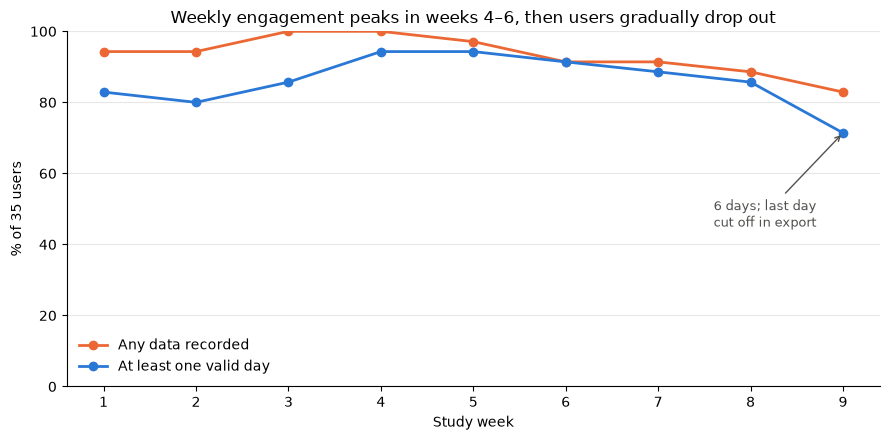

In [6]:
import os
os.makedirs("../docs/figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(weekly.index, weekly["pct_users_in_data"], marker="o", linewidth=2,
        color="#EB6834", label="Any data recorded")
ax.plot(weekly.index, weekly["pct_users_valid"], marker="o", linewidth=2,
        color="#2A78D6", label="At least one valid day")

ax.set_ylim(0, 100)
ax.set_xticks(weekly.index)
ax.set_xlabel("Study week")
ax.set_ylabel(f"% of {n_users} users")
ax.set_title("Weekly engagement peaks in weeks 4–6, then users gradually drop out")
ax.annotate("6 days; last day\ncut off in export", xy=(9, weekly.loc[9, "pct_users_valid"]),
            xytext=(7.6, 45), arrowprops=dict(arrowstyle="->", color="#52514E"),
            color="#52514E", fontsize=9)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")

fig.tight_layout()
fig.savefig("../docs/figures/h1_weekly_engagement.png", dpi=150)
plt.show()

„Engagement does not fade gradually among users who stay: valid-day share and activity are unchanged between the two months. The risks are at both ends: a weaker first two weeks (onboarding) and about one in nine users dropping out entirely within a month.“

In [7]:
from scipy import stats

days_per_period = data["dim_date"].groupby("period").size()

valid_share = (
    daily.groupby(["user_id", "period"])["is_valid_day"].sum()
    .unstack(fill_value=0)
    .div(days_per_period, axis=1)
)

w_share = stats.wilcoxon(valid_share[1], valid_share[2])
print("Valid-day share per user")
print(f"  mean   P1 = {valid_share[1].mean():.3f}, P2 = {valid_share[2].mean():.3f}")
print(f"  median P1 = {valid_share[1].median():.3f}, P2 = {valid_share[2].median():.3f}")
print(f"  lower in P2: {(valid_share[2] < valid_share[1]).sum()} users, "
      f"higher: {(valid_share[2] > valid_share[1]).sum()}, "
      f"equal: {(valid_share[2] == valid_share[1]).sum()}")
print(f"  Wilcoxon signed-rank: W = {w_share.statistic:.1f}, p = {w_share.pvalue:.3f}")

steps = valid.groupby(["user_id", "period"])["total_steps"].mean().unstack().dropna()
w_steps = stats.wilcoxon(steps[1], steps[2])
print(f"\nAverage steps on valid days ({len(steps)} users with valid days in both periods)")
print(f"  mean P1 = {steps[1].mean():.0f}, P2 = {steps[2].mean():.0f}")
print(f"  Wilcoxon signed-rank: W = {w_steps.statistic:.1f}, p = {w_steps.pvalue:.3f}")

Valid-day share per user
  mean   P1 = 0.764, P2 = 0.770
  median P1 = 0.935, P2 = 0.935
  lower in P2: 21 users, higher: 12, equal: 2
  Wilcoxon signed-rank: W = 258.5, p = 0.694

Average steps on valid days (32 users with valid days in both periods)
  mean P1 = 7834, P2 = 7967
  Wilcoxon signed-rank: W = 234.0, p = 0.586
